# Remote UAV control, built from blocks

> The communication model of opportunistic HJB control (oHJB) of a UAV from a base station, as a pipeline of comm-core blocks: aerial path loss, Shannon delays against a deadline, and a power boost when the deadline is at risk.

In oHJB (Shiri, Park and Bennis, *Remote UAV Online Path Planning via Neural Network Based Opportunistic
Control*), a base station (BS) steers a UAV to a destination. In each control round `k`, the UAV sends its state,
the BS updates its controller with it and sends back either an **action** (aHJB) or the **controller itself**
(mHJB), which the UAV then runs on its own. oHJB sends actions first and switches to the controller once it has
seen enough states and the link has become slow.

The communication model (Section III-A) is a chain of steps, and each one is a comm-core block (see `block`).
Built as a `PipelineBackend`, each step can be replaced on its own:

| oHJB | | block |
|---|---|---|
| the path loss: 3GPP's aerial model, line of sight drawn with its probability, constant during a round and independent across rounds | eqs. 11–12 | `UAVPathLoss` (a `Fading`) |
| the power: 20 dBm at the UAV; 23 dBm at the BS, 26 dBm when 23 would miss the deadline | eq. 13 | `DeadlinePower` (a `PowerControl`), or `FixedPower` |
| the SNR, `P · 10^(−L/10) / (N W)` | eq. 10 | `SINR` |
| the delay, `b / (W log₂(1 + SNR))` | eq. 10 | `Capacity` → `Airtime` |
| the deadline: the round's state and reply arrive within `D_th` of the state's measurement, or not at all | Sec. III-A | `Deadline` |
| the payloads: a state is `4b` bits, an action `2b`, the controller `Mb` | Sec. III-B | the messages' `size_bits` |
| the rounds of Algorithms 1–3 | Sec. III | the application: a loop around a `Network` |

The paper's names follow the BS: the *downlink* (DL) is the UAV sending its state to the BS (the BS downloads it),
and the *uplink* (UL) is the BS sending back an action or the controller (uploading it).

**What is not the paper's: the controller.** The paper's HJB NN (eqs. 7–9) is a 54-weight polynomial model trained
at each received state. Its features are sixth powers of positions in metres, and the paper doesn't say how they
are scaled, so it can't be rebuilt as written. It is replaced by the exact solution of the HJB equation for the
quadratic part of the cost (eq. 1 without its first term), whose value function is quadratic: the LQR. It is
reached one update per received state, which plays the same role as the paper's training:

* the controller starts untrained and improves with every state the BS receives;
* it is still `M = 54` weights of `b` bits on the air, as in the paper.

Three other choices aren't the paper's:
* **Acceleration limit.** Accelerations are limited to 1 m/s², which gives at most 10 m/s against the drag. The
  paper's Fig. 2 stays under 8 m/s.
* **Mission end.** The mission ends when the UAV is within 2 m of the destination at under 0.5 m/s. The paper
  doesn't give `r_th` or `v_th`.
* **Distance.** The distance `d` in eqs. 11–12 is the 3-D distance. With `d = ‖r − r_s‖`, as written, it would be
  0 at the start, and eq. 12's `√(d² − h²)` shows `d` includes the altitude.

In [ ]:
import math
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
from scipy.linalg import solve_continuous_are

from comm_core import *

## Settings

As in the paper's Section IV. Powers are in watts, and the noise power is the noise density over the bandwidth.

In [ ]:
dBm = lambda x: 10 ** ((x - 30) / 10)
BS = np.array([150.0, 100.0])                 # the BS, and the UAV's start (r_s); the destination is the origin
ALTITUDE, FC_GHZ, W = 30.0, 2.0, 2e6          # h (m), carrier (GHz), bandwidth (Hz)
NOISE_W = dBm(-118) * W                       # N_i W
P_DL, P_UL, P_UL_MAX = dBm(20), dBm(23), dBm(26)
b, M_WEIGHTS = 80, 54                         # 10 bytes per number; the controller's weights
B_STATE, B_ACTION, B_MODEL = 4 * b, 2 * b, M_WEIGHTS * b
D_TH, ALPHA, N_AVG, DN_TH = 2.0, 0.2, 5, 50   # deadline (s), oHJB's switching rule
C0, C1, C2, C3 = 0.1, 0.015, 0.015, 0.005
V_O, V_NOISE, DT = np.array([1.0, -1.0]), 0.1, 0.1   # mean wind (m/s), its perturbation, the time step (s)
A_MAX, R_TH, V_TH = 1.0, 2.0, 0.5             # not in the paper (see above)

## The blocks

**`UAVPathLoss`** is a `Fading`: it gives each transmission its coefficient `h = 10^(−L/20)`, with `L` from eq. 11.
Line of sight is drawn with eq. 12's probability once per round, so that the round's state and reply see the same
`L` (the paper's fully correlated downlink and uplink). The round is the message's `metadata['control']`, and the UAV's
position comes from `set_positions`, as for any fading that depends on where the nodes are. Its draws use the
block's `rng`, which the network reseeds with every episode.

In [ ]:
class UAVPathLoss(Fading):
    "3GPP TR 36.777's path loss between a ground BS and a UAV (eqs. 11–12): line of sight drawn once per round."

    def __init__(self, bs, altitude, fc_ghz):
        self.bs, self.altitude, self.fc_ghz = np.asarray(bs, float), altitude, fc_ghz
        self.positions, self._rounds = {}, {}

    def reset(self, seed=None):
        super().reset(seed)
        self._rounds = {}                                         # round -> L (dB)

    def set_positions(self, positions):
        self.positions.update(positions)

    def p_los(self, horizontal):
        "Eq. 12, with the horizontal distance √(d² − h²)."
        lh = math.log10(self.altitude)
        d_o, p_o = max(294.05 * lh - 432.94, 18.0), 233.98 * lh - 0.95
        if horizontal <= d_o:
            return 1.0
        return d_o / horizontal + math.exp(-horizontal / p_o) * (1 - d_o / horizontal)

    def path_loss_db(self, d, los):
        "Eq. 11 at the 3-D distance d."
        lh, f = math.log10(self.altitude), 20 * math.log10(self.fc_ghz)
        l_los = 30.9 + (22.25 - 0.5 * lh) * math.log10(d) + f
        return l_los if los else max(l_los, 32.4 + (43.2 - 7.6 * lh) * math.log10(d) + f)

    def coefficient(self, transmission, link):
        k = transmission.message.metadata['control']
        if k not in self._rounds:
            horizontal = float(np.linalg.norm(np.asarray(self.positions['uav'], float) - self.bs))
            los = self.rng.random() < self.p_los(horizontal)
            self._rounds[k] = self.path_loss_db(math.hypot(horizontal, self.altitude), los)
        return 10 ** (-self._rounds[k] / 20)

**`DeadlinePower`** is eq. 13. A power control is given each transmission's `|h|²`, link and message (see
`PowerControl`). It sends at the link's power, unless the delay at that power would exceed the time left
(`metadata['deadline']`, which is `D_th − D_DL` for the BS's reply); then it sends at `max_power`. Only the BS does this.

**`Capacity`** gives the symbols a message takes at the Shannon rate: `b / log₂(1 + SNR)`. `Airtime`, the library's
block, turns symbols into time on the air (symbols / bandwidth) and energy (power × time). Together they are
eq. 10.

**`Deadline`** says what arrives: a message whose delay is within its time left. A late one is cut off at its
deadline, so its energy is only that of the time it was on the air.

In [ ]:
class DeadlinePower(PowerControl):
    "Eq. 13: the link's power, or `max_power` if the delay at the link's power would miss the deadline (the BS only)."

    def __init__(self, max_power, senders=('bs',)):
        self.max_power, self.senders = max_power, senders

    def allocate(self, gain, noise_power, link=None, message=None):
        p = link.tx_power_w
        if link.sender in self.senders:
            expected = message.size_bits / (link.bandwidth_hz * math.log2(1 + p * gain / noise_power))
            if expected > message.metadata['deadline']:
                p = self.max_power
        return p, True


class Capacity(Block):
    "Symbols to send each message at the Shannon rate: size_bits / log2(1 + SNR)."
    outputs = ('num_symbols',)

    def call(self, size_bits, sinr):
        with np.errstate(divide='ignore'):
            symbols = np.ceil(np.asarray(size_bits, float) / np.log2(1 + np.asarray(sinr).mean(1)))
        return np.minimum(symbols, 1e18)                          # no rate at all: as good as never


class Deadline(Block):
    "A message arrives if its delay is within the time it has left (`metadata['deadline']`); a late one is cut off then."
    outputs = ('success', 'energy')

    def call(self, transmission, latency, energy):
        left = np.array([t.message.metadata['deadline'] for t in transmission])
        latency = np.asarray(latency, float)
        with np.errstate(invalid='ignore'):
            sent = np.where(latency > left, np.maximum(left, 0) / latency, 1.0)   # the share of it on the air
        return latency <= left, np.asarray(energy) * sent

## The pipeline

The blocks in order, with the library's `SINR` and `Airtime` between them. The topology has one link per direction,
each with its bandwidth and power:

In [ ]:
def radio(power_control, bs=BS):
    "The communication model of oHJB, as blocks."
    return [UAVPathLoss(bs, ALTITUDE, FC_GHZ), power_control, SINR(), Capacity(), Airtime(), Deadline()]

UAV_BS = Link('uav', 'bs', bandwidth_hz=W, tx_power_w=P_DL)          # the paper's downlink: the state
BS_UAV = Link('bs', 'uav', bandwidth_hz=W, tx_power_w=P_UL)          # the paper's uplink: an action or the model
TOPOLOGY = GraphTopology([UAV_BS, BS_UAV])

backend = PipelineBackend(radio(DeadlinePower(P_UL_MAX)), noise_power=NOISE_W)
print(' → '.join(type(block).__name__ for block in backend.pipeline))
print('inputs:', backend.pipeline.required)
print('outputs:', backend.pipeline.outputs)

UAVPathLoss → DeadlinePower → SINR → Capacity → Airtime → Deadline
inputs: ('transmission', 'link', 'sender', 'receiver', 'size_bits', 'group', 'noise_power')
outputs: ('h', 'power', 'active', 'sinr', 'num_symbols', 'latency', 'energy', 'success')


`PipelineBackend` checks the wiring when it is built. Every input a block needs is either one of the step's
inputs (`transmission`, `link`, `size_bits`, ...), the constant `noise_power`, or given by a block before it.

A check against eq. 10 by hand: a state sent from 100 m in line of sight, through the pipeline.

In [ ]:
def message(sender, receiver, size_bits, k, deadline=D_TH):
    return Message(sender, receiver, None, size_bits=size_bits, metadata={'control': k, 'deadline': deadline})

def rows(messages):
    return [(Transmission(m, m.sender, m.receiver, 0.0), TOPOLOGY.get_link(m.sender, m.receiver)) for m in messages]

pl = UAVPathLoss(BS, ALTITUDE, FC_GHZ)
assert pl.p_los(10.0) == 1.0 and 0 < pl.p_los(300.0) < 1
backend.set_positions({'uav': BS + [100.0, 0.0]})                     # p_LOS = 0.79: draw until a round is in LOS
backend.reset(seed=0)
k = next(k for k in range(100) if (state := backend.pipeline(**step_inputs(rows([message('uav', 'bs', B_STATE, k)])),
                                                             noise_power=NOISE_W))['h'][0, 0] ** 2 > 10 ** (-8.5))
L = pl.path_loss_db(math.hypot(100.0, ALTITUDE), los=True)
expected = B_STATE / (W * math.log2(1 + P_DL * 10 ** (-L / 10) / NOISE_W))
assert abs(state['latency'][0] - expected) < 1 / W and state['success'][0]
print(f'L = {L:.1f} dB, SNR = {10 * math.log10(state["sinr"][0, 0]):.1f} dB, the state takes {1e3 * expected:.2f} ms')

L = 80.3 dB, SNR = -5.4 dB, the state takes 0.43 ms


## The link along the way

How often a round completes (the state and the reply both arrive within `D_th`) depends on how far the UAV is from
the BS and on what the BS sends back. With the pipeline alone, without a network or a UAV: 400 rounds at each
distance, each state sent in one call of the blocks, then the replies with the time each has left. The replies use
the same rounds, and so the same draws of line of sight.

In [ ]:
def completes(power_control, distance, n=400, seed=0):
    "Share of n rounds at `distance` (m, horizontal) whose state and reply both arrive in time, per kind of reply."
    backend = PipelineBackend(radio(power_control), noise_power=NOISE_W)
    backend.reset(seed=seed)
    backend.set_positions({'uav': BS + [distance, 0.0]})
    states = backend.transmit_all(rows([message('uav', 'bs', B_STATE, k) for k in range(n)]))
    out = {}
    for kind, size in (('action', B_ACTION), ('model', B_MODEL)):
        replies = [message('bs', 'uav', size, k, D_TH - r.latency) for k, r in enumerate(states) if r.success]
        out[kind] = sum(r.success for r in backend.transmit_all(rows(replies))) / n
    return out

DISTANCES = np.arange(0, 601, 20)
curves = {(pc, kind): [] for pc in ('PC', 'no PC') for kind in ('action', 'model')}
for pc, make in (('PC', lambda: DeadlinePower(P_UL_MAX)), ('no PC', FixedPower)):
    for d in DISTANCES:
        for kind, share in completes(make(), d).items():
            curves[pc, kind].append(share)
p_los = [UAVPathLoss(BS, ALTITUDE, FC_GHZ).p_los(d) for d in DISTANCES]

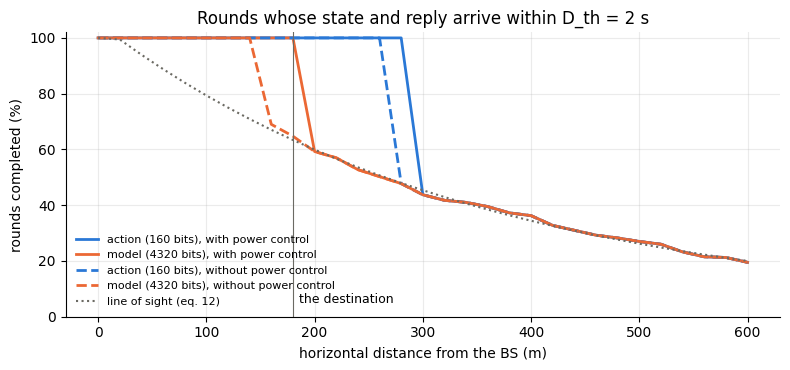

In [ ]:
colors = {'action': '#2a78d6', 'model': '#eb6834'}                  # categorical slots 1 and 2
fig, ax = plt.subplots(figsize=(8, 3.8))
for (pc, kind), y in curves.items():
    ax.plot(DISTANCES, 100 * np.array(y), '-' if pc == 'PC' else '--', color=colors[kind], lw=2,
            label=f'{kind} ({b * M_WEIGHTS if kind == "model" else 2 * b} bits), {"with" if pc == "PC" else "without"} power control')
ax.plot(DISTANCES, 100 * np.array(p_los), ':', color='#6b6a63', lw=1.5, label='line of sight (eq. 12)')
ax.axvline(np.linalg.norm(BS), color='#6b6a63', lw=0.8)
ax.annotate('the destination', (np.linalg.norm(BS), 5), xytext=(4, 0), textcoords='offset points', fontsize=9)
ax.set(xlabel='horizontal distance from the BS (m)', ylabel='rounds completed (%)', ylim=(0, 102),
       title='Rounds whose state and reply arrive within D_th = 2 s')
ax.grid(alpha=0.25)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc='lower left')
plt.tight_layout()
plt.show()

* **An action gets through wherever the state does.** At 160 bits it needs little rate, and a round fails only
  once the state itself takes most of the 2 s. In non-line of sight, that is beyond about 260 m without power
  control and 280 m with it.
* **The controller needs much more.** At 4320 bits (27× an action), it misses the deadline in non-line of sight
  from about 140 m. Eq. 13's 3 dB boost moves that to about 190 m, just past the destination (180 m).
* Beyond those distances, a round completes only in line of sight, which eq. 12 makes rarer with distance.

## The controller

The UAV's state is `s = [r, v]`, and it moves as eq. 3: `ds = (As + B(a + c₀v_o)) dt + G dW`. The quadratic part of
eq. 1's cost is `c₁‖r‖² + c₂‖v‖² + c₃‖a‖²`, whose HJB solution is `ψ = sᵀPs`, with `P` solving the Riccati
equation and `a = −Ks − c₀v_o` (`K = Bᵀ P / c₃`, as eq. 6). The BS starts from `P = 0` and takes one step of the
Riccati equation per state it receives, which is value iteration with a horizon 0.1 s longer per update. The
paper's model starts from `w = 0` (`a = 0`); this one starts by only cancelling the mean wind.

After 50 updates (the paper's `Dn_th`), it is the LQR to within 1%:

In [ ]:
A = np.block([[np.zeros((2, 2)), np.eye(2)], [np.zeros((2, 2)), -C0 * np.eye(2)]])
B = np.vstack([np.zeros((2, 2)), np.eye(2)])
Q, R = np.diag([C1, C1, C2, C2]), C3 * np.eye(2)

def train(P, step=0.1):
    "One update of the BS's controller: a step of the Riccati equation (value iteration)."
    return P + step * (A.T @ P + P @ A - P @ B @ np.linalg.solve(R, B.T @ P) + Q)

def model(P):
    "The weights the BS uploads: the feedback gain K."
    return np.linalg.solve(R, B.T @ P)

def act(K, s):
    "The action of the controller K at state s (eq. 6), at most A_MAX."
    a = -K @ s - C0 * V_O
    return a * min(1.0, A_MAX / np.linalg.norm(a))

P = np.zeros((4, 4))
error = []
for n in range(100):
    P = train(P)
    error.append(np.abs(model(P) - model(solve_continuous_are(A, B, Q, R))).max() / model(solve_continuous_are(A, B, Q, R)).max())
assert error[49] < 0.01 and error[9] > 0.3
print(f'after 10 updates: {100 * error[9]:.0f}% off; after 50: {100 * error[49]:.2f}%')

after 10 updates: 35% off; after 50: 0.00%


## The rounds

Algorithms 1–3, around a `Network` with this pipeline as its backend. In round `k`:

1. At `t_o,k` the UAV sends its state (`4b` bits). If it arrives within `D_th`, after `D_DL`:
2. the BS updates its controller and, at `t_o,k + D_DL`, sends an action or the controller, with `D_th − D_DL` left.
   The action is computed from the state the BS received, which is `D_DL` old.
3. The UAV acts with the most recent action it received, held until the next one, or with the most recent
   controller it received, applied to its current state every `Δt`.
4. The next round starts when the reply arrives, or at `D_th` if something was lost, on the grid of `Δt`.

oHJB switches to the controller when it has received `Dn_th` states and the mean delay of the last `N` received
states exceeds `αD_th`, and stays with it, as the paper's text and Fig. 2 describe. Algorithm 3's line 5 says
"`Dn ≥ Dn_th` **or** `D̄ ≤ αD_th`" for actions, which contradicts the text. `Dn` and `Up` count the received states
and the received replies.

In [ ]:
RULES = {
    'aHJB': lambda dn, delay: 'action',
    'mHJB': lambda dn, delay: 'model',
    'oHJB': lambda dn, delay: 'model' if dn >= DN_TH and delay > ALPHA * D_TH else 'action',
}

def fly(rule, power_control, seed, bs=BS, t_max=600.0):
    "One mission from the BS to the origin: travel time T (inf: not reached), motion energy E(T), and the rounds."
    backend = PipelineBackend(radio(power_control, bs), noise_power=NOISE_W)
    net = Network([Node('uav'), Node('bs')], TOPOLOGY, IdealProtocol(), backend)
    net.reset(seed=seed)
    wind = np.random.default_rng(seed)
    s, t, k, P = np.r_[bs, 0.0, 0.0], 0.0, 0, np.zeros((4, 4))
    held, controller, arriving = np.zeros(2), None, deque()       # what the UAV acts with; replies on their way
    dn, up, delays, switched, energy, log = 0, 0, deque(maxlen=N_AVG), None, 0.0, []
    while t < t_max and not (np.linalg.norm(s[:2]) <= R_TH and np.linalg.norm(s[2:]) <= V_TH):
        backend.set_positions({'uav': s[:2].copy()})
        net.send(Message('uav', 'bs', s.copy(), size_bits=B_STATE, metadata={'control': k, 'deadline': D_TH}))
        [state] = net.step_to(t)
        end = t + D_TH
        if state.success:                                         # the BS has the state, D_DL after t_o,k
            dn += 1
            delays.append(state.latency)
            P = train(P)
            kind = 'model' if switched is not None else RULES[rule](dn, np.mean(delays))
            if kind == 'model' and switched is None:
                switched = t
            content = act(model(P), state.payload) if kind == 'action' else model(P)
            net.send(Message('bs', 'uav', content, size_bits=B_ACTION if kind == 'action' else B_MODEL,
                             metadata={'control': k, 'deadline': D_TH - state.latency}), at=t + state.latency)
            [reply] = net.step_to(t + state.latency)
            if reply.success:
                up += 1
                end = t + state.latency + reply.latency
                arriving.append((end, kind, reply.payload))
        steps = max(1, math.ceil((end - t) / DT - 1e-9))
        for i in range(steps):                                    # the UAV flies until the next round
            while arriving and arriving[0][0] <= t + i * DT + 1e-9:
                _, kind, content = arriving.popleft()
                held, controller = (content, None) if kind == 'action' else (held, content)
            a = act(controller, s) if controller is not None else held
            energy += (C2 * s[2:] @ s[2:] + C3 * a @ a) * DT
            s = s + np.r_[s[2:], -C0 * s[2:] + a + C0 * V_O] * DT + np.r_[0, 0, V_NOISE * math.sqrt(DT) * wind.standard_normal(2)]
        log.append((t, s[0], s[1], dn, up))
        t, k = t + steps * DT, k + 1
    reached = np.linalg.norm(s[:2]) <= R_TH and np.linalg.norm(s[2:]) <= V_TH
    return dict(T=t if reached else math.inf, E=energy, dn=dn, up=up, switched=switched if rule == 'oHJB' else None,
                comm=net.metrics.summary().total_energy, log=np.array(log))

## At the paper's distance

Each method with and without the power boost, over 8 missions (seeds: the wind and the line of sight):

In [ ]:
SEEDS = range(8)
POWER = {'PC': lambda: DeadlinePower(P_UL_MAX), 'no PC': FixedPower}

def table(bs=BS, power=POWER):
    runs = {(pc, rule): [fly(rule, make(), seed, bs) for seed in SEEDS] for pc, make in power.items() for rule in RULES}
    print(f'{"":14s}{"reached":>9s}{"T (s)":>8s}{"E(T)":>8s}{"Dn":>6s}{"Up":>6s}{"radio (J)":>11s}{"switch (s)":>12s}')
    for (pc, rule), rs in runs.items():
        T = np.array([r['T'] for r in rs])
        switch = [r['switched'] for r in rs if r['switched'] is not None]
        print(f'{rule + ", " + pc:14s}{np.mean(np.isfinite(T)):9.0%}{np.median(T):8.1f}{np.median([r["E"] for r in rs]):8.1f}'
              f'{np.median([r["dn"] for r in rs]):6.0f}{np.median([r["up"] for r in rs]):6.0f}'
              f'{np.median([r["comm"] for r in rs]):11.2f}{np.median(switch) if switch else math.nan:12.1f}')
    return runs

runs = table()

                reached   T (s)    E(T)    Dn    Up  radio (J)  switch (s)
aHJB, PC           100%    48.2    22.5   317   317       2.28         nan
mHJB, PC           100%    41.6    21.7   216   212       6.20         nan
oHJB, PC           100%    46.3    22.5   288   287       3.77        35.3
aHJB, no PC        100%    48.2    22.5   317   317       2.28         nan
mHJB, no PC        100%    41.2    21.7   214   207       3.90         nan
oHJB, no PC        100%    46.9    22.7   290   285       2.89        35.3


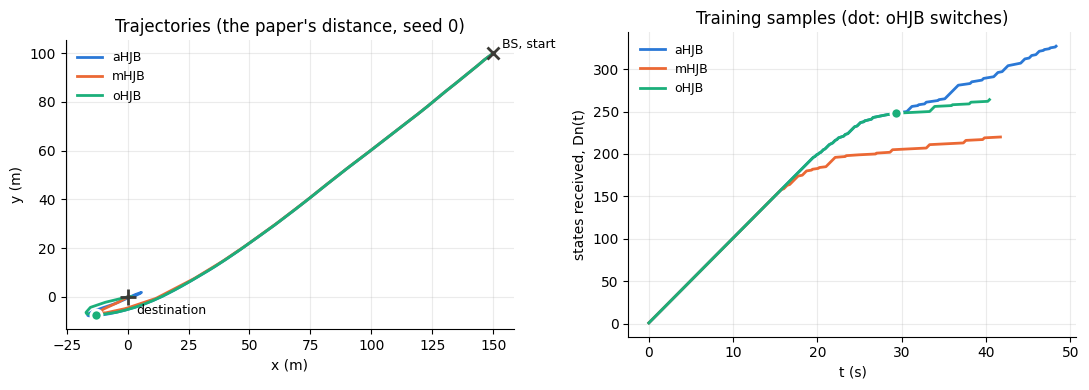

In [ ]:
COLORS = {'aHJB': '#2a78d6', 'mHJB': '#eb6834', 'oHJB': '#1baf7a'}   # categorical slots 1-3

def show(runs, bs, title, seed=0):
    "The trajectories of one mission per method (with power control), and the states each received."
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    for rule, color in COLORS.items():
        r = runs['PC', rule][seed]
        t, x, y, dn, up = r['log'].T
        ax1.plot(x, y, color=color, lw=2, label=f'{rule}' + ('' if math.isfinite(r['T']) else ' (not reached)'))
        ax2.plot(t, dn, color=color, lw=2, label=rule)
        if r['switched'] is not None:
            i = np.searchsorted(t, r['switched'])
            for ax, point in ((ax1, (x[i], y[i])), (ax2, (t[i], dn[i]))):
                ax.plot(*point, 'o', color=color, ms=8, mec='white', mew=2)
    ax1.plot(*bs, 'x', color='#3b3a36', ms=9, mew=2)
    ax1.annotate('BS, start', bs, xytext=(6, 4), textcoords='offset points', fontsize=9)
    ax1.plot(0, 0, '+', color='#3b3a36', ms=11, mew=2)
    ax1.annotate('destination', (0, 0), xytext=(6, -12), textcoords='offset points', fontsize=9)
    ax1.set(xlabel='x (m)', ylabel='y (m)', title=f'Trajectories ({title}, seed {seed})', aspect='equal')
    ax2.set(xlabel='t (s)', ylabel='states received, Dn(t)', title='Training samples (dot: oHJB switches)')
    for ax in (ax1, ax2):
        ax.grid(alpha=0.25)
        for side in ('top', 'right'):
            ax.spines[side].set_visible(False)
        ax.legend(frameon=False, fontsize=9)
    plt.tight_layout()
    plt.show()

show(runs, BS, "the paper's distance")

* **All three methods reach the destination, with or without power control.** Within 180 m, the link serves all
  of them.
* **mHJB is the fastest: 41.6 s, against 48.2 s for aHJB and 46.3 s for oHJB.** With the controller on board, the
  UAV acts on its current state every 0.1 s. An action is computed from the state at the start of the round and
  held until the next one arrives, so near the destination the UAV corrects late and takes longer to settle.
* **More training samples buy nothing here.** aHJB receives the most states (317, against 216 for mHJB). But the
  stand-in controller is fully trained after 50 of them, in the first 5 s, while the UAV is close to the BS and
  every reply takes under 0.1 s. That removes the paper's reason to send actions first. Its HJB NN trains slowly,
  so there the extra samples matter.
* **Power control matters only for mHJB, and little.** It boosts the controller's uploads in non-line of sight
  beyond 140 m. A lost upload leaves the UAV with the previous controller, already trained, so the travel time
  barely changes (41.6 s against 41.2 s), while the radio energy goes from 3.9 J to 6.2 J. Actions never need the
  boost within 180 m.
* **oHJB switches at about 35 s (the median),** once its last five states took 0.4 s on average. That happens in
  non-line of sight, far out.

## Farther from the base station

The same mission with the BS (and the start) 2× and 3× as far from the destination, 361 m and 541 m. Power
control is on: beyond about 300 m, a round in non-line of sight loses the state itself, before the BS could boost
anything (the figure above).

In [ ]:
far = {scale: table(BS * scale, {'PC': POWER['PC']}) for scale in (2, 3)}

                reached   T (s)    E(T)    Dn    Up  radio (J)  switch (s)
aHJB, PC             0%     inf   268.3   462   458      56.85         nan
mHJB, PC           100%    63.5    48.2   218   212       7.26         nan
oHJB, PC           100%    61.8    48.2   276   272       4.79        32.6


                reached   T (s)    E(T)    Dn    Up  radio (J)  switch (s)
aHJB, PC             0%     inf   406.0   358   358      57.29         nan
mHJB, PC           100%    81.4    74.8   220   214       8.97         nan
oHJB, PC           100%    79.9    74.8   278   274       6.59        32.7


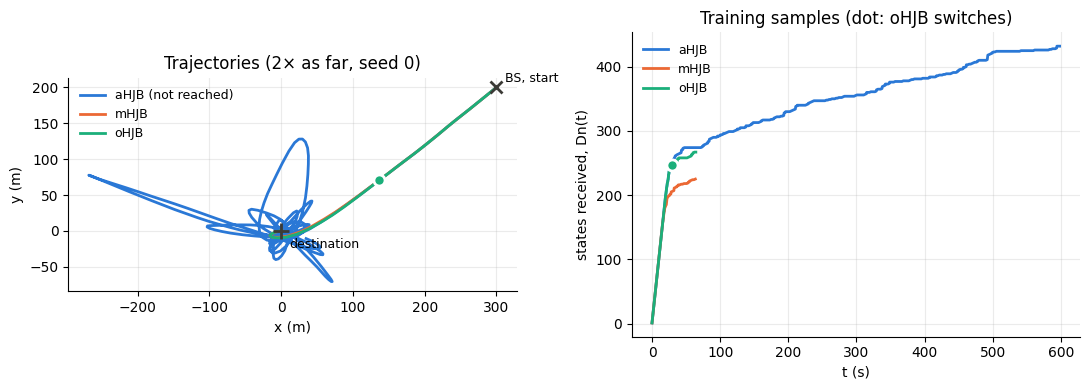

In [ ]:
show(far[2], 2 * BS, '2× as far')

* **aHJB never arrives.** Beyond 300 m, a round in non-line of sight loses the state, and the UAV holds its last
  action for the whole 2 s, often for several rounds in a row. A saturated action held that long overshoots, which
  takes the UAV farther from the BS, where more rounds are lost. In the figure, it circles the destination, as far
  as 270 m from it, until the 600 s limit. This is the failure the paper reports for aHJB.
* **mHJB and oHJB arrive every time, within 2.5% of each other's travel time:** 63.5 s and 61.8 s at 2×, 81.4 s
  and 79.9 s at 3×. A UAV that runs its controller loses nothing when a round is lost.
* **oHJB uses about a third less radio energy than mHJB:** 4.8 J against 7.3 J at 2×, and 6.6 J against 9.0 J at
  3×. Near the BS, actions do as well as the controller at 1/27 of the size. oHJB switches at about 33 s, once the
  rounds slow down.

**Against the paper.** The communication model gives the paper's trade-off: actions are cheap and work while the
link holds, and only a controller on board survives losing it. oHJB arrives whenever mHJB does. Its travel time is
within 2.5% of mHJB's far from the BS and 11% longer at the paper's distance, and it uses the least radio energy
of the methods that arrive far out. The paper also finds oHJB 13% faster than both, and mHJB failing without power
control. Those results depend on how slowly its HJB NN trains, which the stand-in controller doesn't reproduce.
Replacing the controller is a change to the application only. The blocks and the network stay as they are.